# Handwritten Digit Recognition
Mini project for ML Fundamentals - classifying digits 0-9 using KNN, Logistic Regression, MLP and PCA

In [11]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits, fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

## Part 1: load_digits dataset (8x8)

In [12]:
# load built-in digits dataset
digits = load_digits()
X = digits.data
y = digits.target

print("data shape:", X.shape)
print("labels:", np.unique(y))

# normalize pixel values from 0-16 to 0-1
X_norm = X / 16.0

data shape: (1797, 64)
labels: [0 1 2 3 4 5 6 7 8 9]


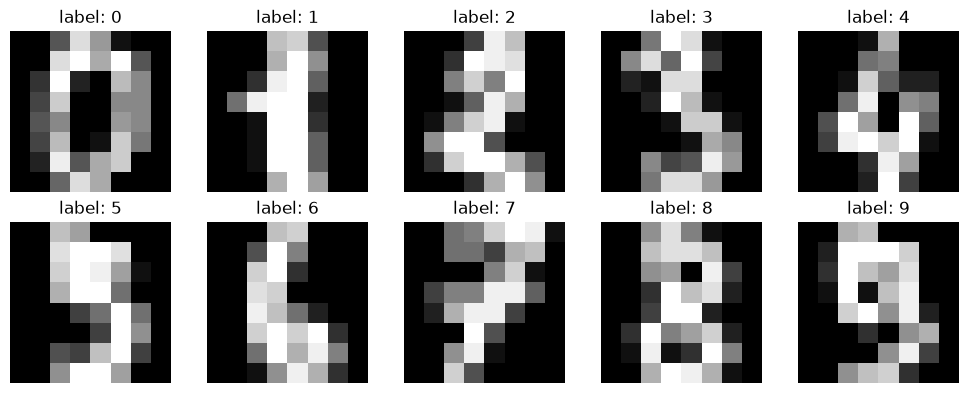

In [13]:
# plot first 10 sample images with labels
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"label: {y[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [14]:
# train test split
X_train, X_test, y_train, y_test = train_test_split(
    X_norm, y, test_size=0.2, random_state=42, stratify=y
)
print("train size:", X_train.shape[0], "test size:", X_test.shape[0])

train size: 1437 test size: 360


In [15]:
# models without PCA
results = []
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(64,), max_iter=500, random_state=42),
}
trained_models = {}

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    acc = accuracy_score(y_test, model.predict(X_test))
    trained_models[name] = model
    results.append({"Model": name, "PCA": "No", "Accuracy": round(acc, 4), "Train Time (s)": round(train_time, 4)})
    print(f"{name} (no PCA) -> acc: {acc:.4f}, time: {train_time:.4f}s")

KNN (no PCA) -> acc: 0.9833, time: 0.0010s
Logistic Regression (no PCA) -> acc: 0.9556, time: 0.0393s
MLP (no PCA) -> acc: 0.9806, time: 0.4300s


In [16]:
# apply PCA (keep 95% variance)
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print("original features:", X_train.shape[1], "-> pca features:", X_train_pca.shape[1])

models_pca = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(64,), max_iter=500, random_state=42),
}

for name, model in models_pca.items():
    start = time.time()
    model.fit(X_train_pca, y_train)
    train_time = time.time() - start
    acc = accuracy_score(y_test, model.predict(X_test_pca))
    results.append({"Model": name, "PCA": "Yes", "Accuracy": round(acc, 4), "Train Time (s)": round(train_time, 4)})
    print(f"{name} (with PCA) -> acc: {acc:.4f}, time: {train_time:.4f}s")

original features: 64 -> pca features: 28
KNN (with PCA) -> acc: 0.9806, time: 0.0007s
Logistic Regression (with PCA) -> acc: 0.9556, time: 0.0079s
MLP (with PCA) -> acc: 0.9806, time: 0.3214s


In [17]:
df_res = pd.DataFrame(results)
df_res

,Model,PCA,Accuracy,Train Time (s)
0,KNN,No,0.9833,0.0010
1,Logistic Regression,No,0.9556,0.0393
2,MLP,No,0.9806,0.4300
3,KNN,Yes,0.9806,0.0007
4,Logistic Regression,Yes,0.9556,0.0079
5,MLP,Yes,0.9806,0.3214


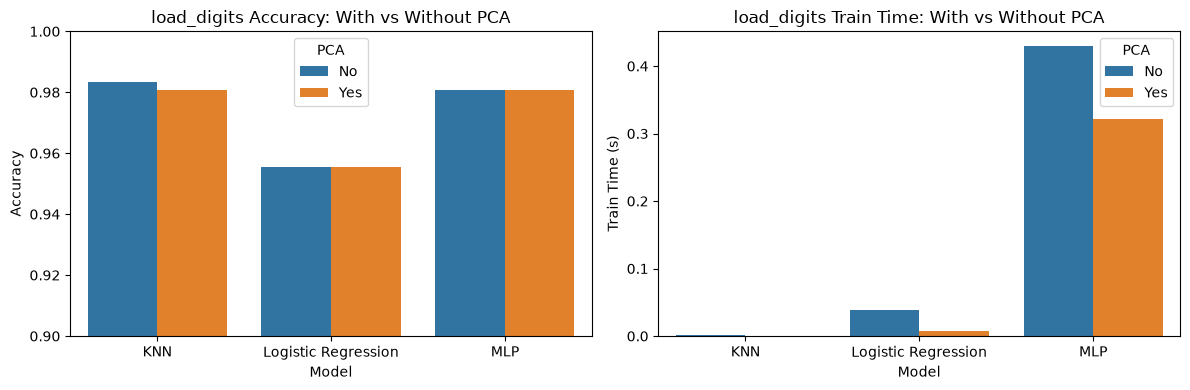

In [18]:
# plot accuracy and training time
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df_res, x="Model", y="Accuracy", hue="PCA", ax=axes[0])
axes[0].set_title("load_digits Accuracy: With vs Without PCA")
axes[0].set_ylim(0.9, 1.0)
sns.barplot(data=df_res, x="Model", y="Train Time (s)", hue="PCA", ax=axes[1])
axes[1].set_title("load_digits Train Time: With vs Without PCA")
plt.tight_layout()
plt.show()

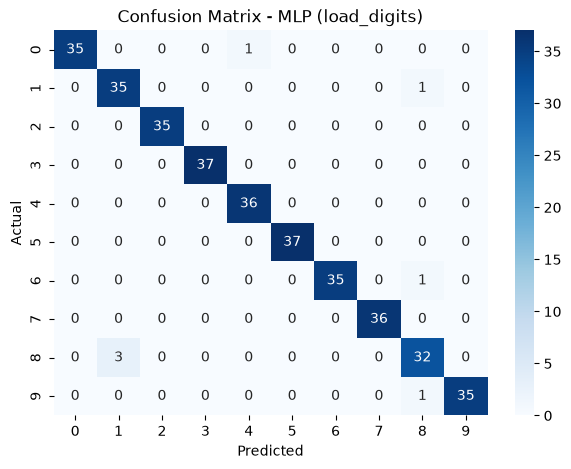

most confused pairs (actual -> predicted):
  8 -> 1 : 3 times
  0 -> 4 : 1 times
  1 -> 8 : 1 times
  6 -> 8 : 1 times
  9 -> 8 : 1 times


In [19]:
# confusion matrix for MLP
digits_best = trained_models["MLP"]
cm = confusion_matrix(y_test, digits_best.predict(X_test))
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - MLP (load_digits)")
plt.show()

cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)
print("most confused pairs (actual -> predicted):")
for _ in range(5):
    idx = np.unravel_index(np.argmax(cm_no_diag), cm_no_diag.shape)
    if cm_no_diag[idx] == 0:
        break
    print(f"  {idx[0]} -> {idx[1]} : {cm_no_diag[idx]} times")
    cm_no_diag[idx] = 0

## Part 2: MNIST dataset (28x28) improvement

In [20]:
# load mnist (70000 images of 28x28)
mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="liac-arff")
Xm = mnist.data.astype(np.float32) / 255.0
ym = mnist.target.astype(int)
print("mnist shape:", Xm.shape)

Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    Xm, ym, test_size=10000, random_state=42, stratify=ym
)

mnist shape: (70000, 784)


In [21]:
# mnist models without PCA
mnist_results = []
mnist_models = {
    "KNN": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=200, tol=1e-3, random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(128,), max_iter=30, early_stopping=True, random_state=42),
}
mnist_trained = {}

for name, model in mnist_models.items():
    start = time.time()
    model.fit(Xm_train, ym_train)
    train_time = time.time() - start
    acc = accuracy_score(ym_test, model.predict(Xm_test))
    mnist_trained[name] = model
    mnist_results.append({"Model": name, "PCA": "No", "Accuracy": round(acc, 4), "Train Time (s)": round(train_time, 4)})
    print(f"MNIST {name} (no PCA) -> acc: {acc:.4f}, time: {train_time:.4f}s")

MNIST KNN (no PCA) -> acc: 0.9717, time: 0.0178s
MNIST Logistic Regression (no PCA) -> acc: 0.9208, time: 0.5910s
MNIST MLP (no PCA) -> acc: 0.9791, time: 4.0711s


/Users/danishshaikh1423/Desktop/ML_mini/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


In [22]:
# mnist with PCA
pca_m = PCA(n_components=0.95, random_state=42)
Xm_train_pca = pca_m.fit_transform(Xm_train)
Xm_test_pca = pca_m.transform(Xm_test)
print("mnist features:", Xm_train.shape[1], "-> pca features:", Xm_train_pca.shape[1])

mnist_models_pca = {
    "KNN": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=200, tol=1e-3, random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(128,), max_iter=30, early_stopping=True, random_state=42),
}

for name, model in mnist_models_pca.items():
    start = time.time()
    model.fit(Xm_train_pca, ym_train)
    train_time = time.time() - start
    acc = accuracy_score(ym_test, model.predict(Xm_test_pca))
    mnist_results.append({"Model": name, "PCA": "Yes", "Accuracy": round(acc, 4), "Train Time (s)": round(train_time, 4)})
    print(f"MNIST {name} (with PCA) -> acc: {acc:.4f}, time: {train_time:.4f}s")

mnist features: 784 -> pca features: 154
MNIST KNN (with PCA) -> acc: 0.9732, time: 0.0027s
MNIST Logistic Regression (with PCA) -> acc: 0.9215, time: 0.2559s
MNIST MLP (with PCA) -> acc: 0.9797, time: 2.3383s


/Users/danishshaikh1423/Desktop/ML_mini/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


In [23]:
df_mnist = pd.DataFrame(mnist_results)
df_mnist

,Model,PCA,Accuracy,Train Time (s)
0,KNN,No,0.9717,0.0178
1,Logistic Regression,No,0.9208,0.5910
2,MLP,No,0.9791,4.0711
3,KNN,Yes,0.9732,0.0027
4,Logistic Regression,Yes,0.9215,0.2559
5,MLP,Yes,0.9797,2.3383


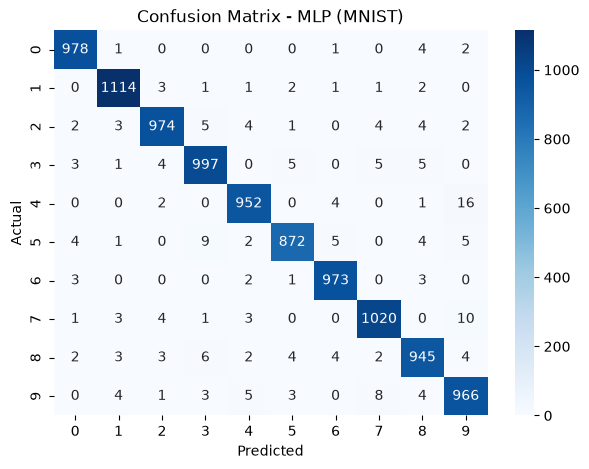

In [24]:
# mnist confusion matrix
mnist_best = mnist_trained["MLP"]
cm_m = confusion_matrix(ym_test, mnist_best.predict(Xm_test))
plt.figure(figsize=(7, 5))
sns.heatmap(cm_m, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - MLP (MNIST)")
plt.show()

## Save both models for Streamlit

In [25]:
joblib.dump(digits_best, "digits_model.pkl")
joblib.dump(mnist_best, "mnist_model.pkl")
np.savez(
    "sample_digits.npz",
    digits_images=X_test[:100].reshape(-1, 8, 8),
    digits_labels=y_test[:100],
    mnist_images=Xm_test[:100].reshape(-1, 28, 28),
    mnist_labels=ym_test[:100],
)
print("saved digits_model.pkl, mnist_model.pkl and sample_digits.npz")

saved digits_model.pkl, mnist_model.pkl and sample_digits.npz
